### 1. Import Dependencies

In [13]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)
dependency_location = os.getenv("DEPENDENCY_LOCATION")
feature_engineered_location = os.getenv("FEATURE_ENGINEERED_LOCATION")
data_processed_location = os.getenv("DATA_PROCESSED_LOCATION")
models_location = os.getenv("MODELS_LOCATION")

In [15]:
import subprocess
import sys

if os.path.isfile(dependency_location):
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "-r", dependency_location
    ])
else:
    print("Requirements file not found!")

In [18]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)
from matplotlib import pyplot as plt 
from imblearn.over_sampling import SMOTE

### 2. Read the dataset

In [19]:
df = pd.read_csv(feature_engineered_location)
df.head()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,...,InternetService_DSL,InternetService_Fiber optic,InternetService_No,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,-1.277445,0,0,0,1,0,0,...,1,0,0,1,0,0,0,0,1,0
1,0,0,0,0.066327,1,0,1,0,1,0,...,1,0,0,0,1,0,0,0,0,1
2,0,0,0,-1.236724,1,0,1,1,0,0,...,1,0,0,1,0,0,0,0,0,1
3,0,0,0,0.514251,0,0,1,0,1,1,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,-1.236724,1,0,0,0,0,0,...,0,1,0,1,0,0,0,0,1,0


#### 3 Train-Test Split

In [20]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)
print("Churn rate train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

(5634, 30) (1409, 30)
Churn rate train: 0.266 | test: 0.265


In [21]:
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

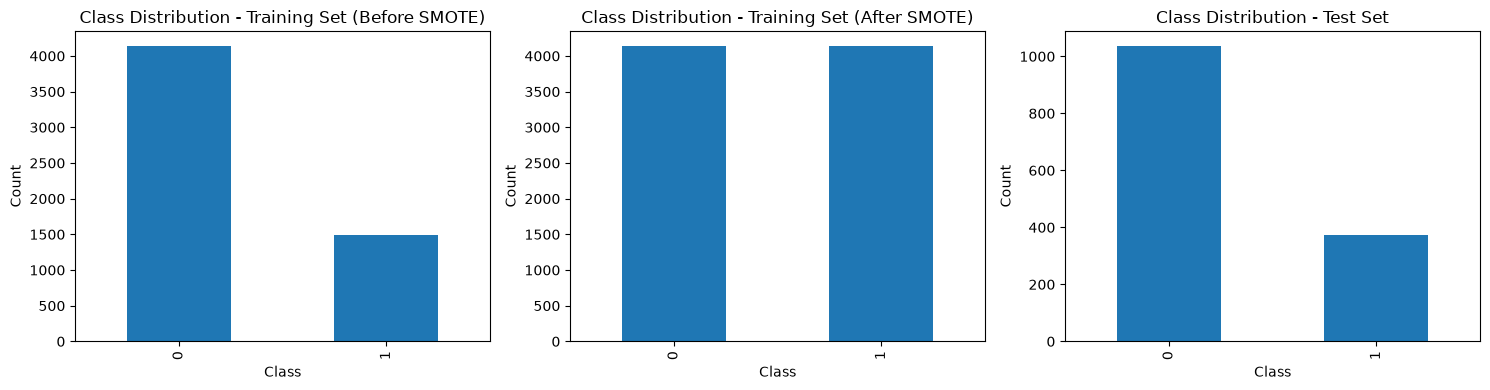

In [26]:
plt.figure(figsize=(15, 4))

# 1. Before SMOTE
plt.subplot(131)
y_train.value_counts().plot(kind='bar')
plt.title('Class Distribution - Training Set (Before SMOTE)')
plt.xlabel('Class')
plt.ylabel('Count')

# 2. After SMOTE
plt.subplot(132)
y_train_resampled.value_counts().plot(kind='bar')
plt.title('Class Distribution - Training Set (After SMOTE)')
plt.xlabel('Class')
plt.ylabel('Count')

# 3. Test Set
plt.subplot(133)
y_test.value_counts().plot(kind='bar')
plt.title('Class Distribution - Test Set')
plt.xlabel('Class')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


In [28]:
split_dir = data_processed_location

X_train_resampled.to_csv(os.path.join(split_dir, "X_train.csv"), index=False)
X_test.to_csv(os.path.join(split_dir, "X_test.csv"), index=False)
y_train_resampled.to_csv(os.path.join(split_dir, "y_train.csv"), index=False)
y_test.to_csv(os.path.join(split_dir, "y_test.csv"), index=False)